# AAI 520-02 – Natural Language Processing

## Assignment 5.1: Prompt Engineering

**Student:** Marcelo Salvador

**Course:** AAI 520 – Natural Language Processing

**Instructor:** Mirsardar Esmaeili

**University:** University of San Diego

**Date:** October 2nd, 2026

---

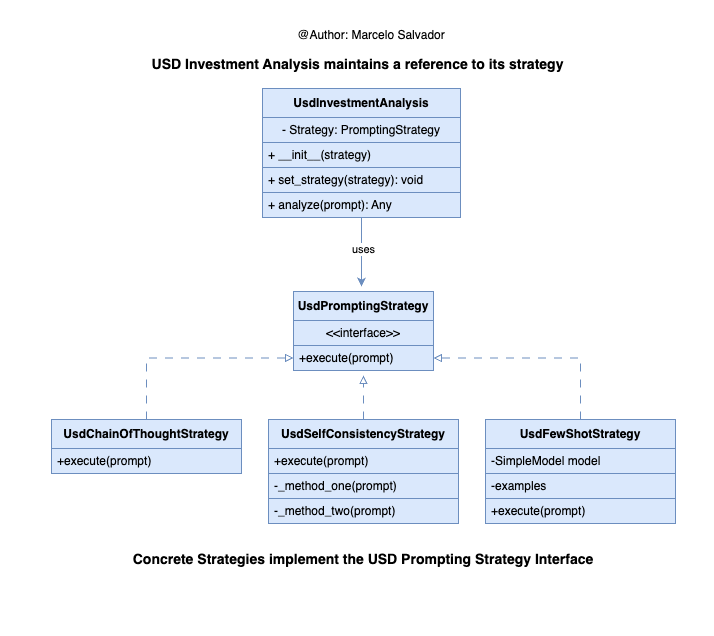

## Create Few Examples:


In [1]:
from investment_prompting.models.simple_model import SimpleModel
from investment_prompting.domain.usd_training import UsdTraining

examples = [
    UsdTraining(
        prompt="Is a 5% annual return good?",
        response=(
            "The quality of a 5% return depends "
            "inflation, investment horizone, and risk."
        ),
    ),
    UsdTraining(
        prompt="What does an annual fee do?",
        response=(
            "An annual fee reduces the investment "
            "balance and lowers long term "
            "investment growth."
        ),
    ),
]


## 1. Chain of Thought Prompting

In [2]:
from investment_prompting.strategies.usd_chain_of_thought_strategy import (
    UsdChainOfThoughtStrategy,
)


def chain_of_thought(prompt):
    strategy = UsdChainOfThoughtStrategy()
    return strategy.execute(prompt)


prompt = {
    "initial_amount": 20000,
    "annual_return": 0.08,
    "annual_fee": 0.01,
    "tax_rate": 0.20,
    "years": 5,
}


result = chain_of_thought(prompt)


print("CHAIN OF THOUGHT INVESTMENT CALCULATION")
print("-" * 50)

for log in result["result_logs"]:

    print(f"Year {log['year']}")
    print(
        f"Beginning Balance: "
        f"${log['beginning_balance']:,.2f}"
    )
    print(
        f"Return Earned: "
        f"${log['earned_return']:,.2f}"
    )
    print(
        f"Tax Deducted: "
        f"${log['tax_deducted']:,.2f}"
    )
    print(
        f"Annual Fee: "
        f"${log['deducted_fee']:,.2f}"
    )
    print(
        f"Ending Balance: "
        f"${log['ending_balance']:,.2f}"
    )

    print("-" * 30)


print(
    f"Final Investment Value: "
    f"${result['final_value']:,.2f}"
)

CHAIN OF THOUGHT INVESTMENT CALCULATION
--------------------------------------------------
Year 1
Beginning Balance: $20,000.00
Return Earned: $1,600.00
Tax Deducted: $320.00
Annual Fee: $212.80
Ending Balance: $21,067.20
------------------------------
Year 2
Beginning Balance: $21,067.20
Return Earned: $1,685.38
Tax Deducted: $337.08
Annual Fee: $224.16
Ending Balance: $22,191.35
------------------------------
Year 3
Beginning Balance: $22,191.35
Return Earned: $1,775.31
Tax Deducted: $355.06
Annual Fee: $236.12
Ending Balance: $23,375.48
------------------------------
Year 4
Beginning Balance: $23,375.48
Return Earned: $1,870.04
Tax Deducted: $374.01
Annual Fee: $248.72
Ending Balance: $24,622.79
------------------------------
Year 5
Beginning Balance: $24,622.79
Return Earned: $1,969.82
Tax Deducted: $393.96
Annual Fee: $261.99
Ending Balance: $25,936.66
------------------------------
Final Investment Value: $25,936.66


## 2. Self-Consistency Chain of Thought

In [3]:
from investment_prompting.strategies.usd_self_consistency_strategy import (
    UsdSelfConsistencyStrategy,
)

strategy = UsdSelfConsistencyStrategy()

result = strategy.execute(prompt)

print("SELF CONSISTENCY RESULTS")
print("-" * 50)

print("\nREASONING METHOD ONE")
print("Year-by-Year Calculation")

for log in result["method_one_logs"]:

    print(f"\nYear {log['year']}")
    print(
        f"Beginning Balance: "
        f"${log['beginning_balance']:,.2f}"
    )
    print(
        f"Return Earned: "
        f"${log['return_earned']:,.2f}"
    )
    print(
        f"Tax Deducted: "
        f"${log['tax_deducted']:,.2f}"
    )
    print(
        f"Annual Fee: "
        f"${log['deducted_fee']:,.2f}"
    )
    print(
        f"Ending Balance: "
        f"${log['ending_balance']:,.2f}"
    )


print("\nREASONING METHOD TWO")
print("Compound Growth Formula")

method_two = result["method_two_logs"]

print(
    f"Growth Factor: "
    f"{method_two['growth_factor']}"
)

print(
    f"Final Value: "
    f"${method_two['final_value']:,.2f}"
)


print("\nCOMPARISON")
print(
    f"Method One: "
    f"${result['reasoning_method_one']:,.2f}"
)

print(
    f"Method Two: "
    f"${result['reasoning_method_two']:,.2f}"
)

print(
    f"Consistent: "
    f"{result['existent_consistency']}"
)

print(
    f"Difference: "
    f"${result['difference']:,.2f}"
)

SELF CONSISTENCY RESULTS
--------------------------------------------------

REASONING METHOD ONE
Year-by-Year Calculation

Year 1
Beginning Balance: $20,000.00
Return Earned: $1,600.00
Tax Deducted: $320.00
Annual Fee: $212.80
Ending Balance: $21,067.20

Year 2
Beginning Balance: $21,067.20
Return Earned: $1,685.38
Tax Deducted: $337.08
Annual Fee: $224.16
Ending Balance: $22,191.35

Year 3
Beginning Balance: $22,191.35
Return Earned: $1,775.31
Tax Deducted: $355.06
Annual Fee: $236.12
Ending Balance: $23,375.48

Year 4
Beginning Balance: $23,375.48
Return Earned: $1,870.04
Tax Deducted: $374.01
Annual Fee: $248.72
Ending Balance: $24,622.79

Year 5
Beginning Balance: $24,622.79
Return Earned: $1,969.82
Tax Deducted: $393.96
Annual Fee: $261.99
Ending Balance: $25,936.66

REASONING METHOD TWO
Compound Growth Formula
Growth Factor: 1.05336
Final Value: $25,936.66

COMPARISON
Method One: $25,936.66
Method Two: $25,936.66
Consistent: True
Difference: $0.00


## 3. Few-Shot Prompting

In [4]:
from investment_prompting.models.simple_model import SimpleModel
from investment_prompting.domain.usd_training import UsdTraining
from investment_prompting.strategies.usd_few_shot_strategy import (
    UsdFewShotStrategy,
)


# Create model

simpleModel = SimpleModel()


# Create Few-Shot strategy

few_shot_strategy = UsdFewShotStrategy(
    model=simpleModel,
    examples=examples,
)


# Target prompt

target_prompt = (
    "How annual fees affect long term investment?"
)


# Execute Few-Shot strategy

few_shot_result = few_shot_strategy.execute(
    target_prompt
)


# Display results

print("FEW SHOT PROMPTING")
print("-" * 50)

print(
    f"Number of examples: "
    f"{len(simpleModel.examples)}"
)

print()


for index, example in enumerate(
    simpleModel.examples,
    start=1,
):
    print(f"Example {index}")
    print(f"Prompt: {example.prompt}")
    print(f"Response: {example.response}")
    print()


print("Target Prompt:")
print(target_prompt)

print()

print("Prediction:")
print(few_shot_result)

FEW SHOT PROMPTING
--------------------------------------------------
Number of examples: 2

Example 1
Prompt: Is a 5% annual return good?
Response: The quality of a 5% return depends inflation, investment horizone, and risk.

Example 2
Prompt: What does an annual fee do?
Response: An annual fee reduces the investment balance and lowers long term investment growth.

Target Prompt:
How annual fees affect long term investment?

Prediction:
2 provided.Few shot examples to process: How annual fees affect long term investment?


## 4. Summary Conclusion

The three prompting approaches showed different ways of improving the structure of the investment analysis.

The **Chain of Thought** prompting broke the calculation investment into yearly steps which makes the effects of taxes, annual fees and the effects of annual return easier to inspect. The initial investment value of $20,000 result in a final investment value of $25,936.66 after five years.

**Self Consistency Chain of Thought Prompting** calculated the final investment value using two different methods where both methods produced the same final value with not difference in dollar amount indicating calculation consistency. The first method calculated the investment yearly, while the second used a compound growth formula. Both approaches produced a final value of $25,936.66 with a $0.00 difference which indicates the calculations were consistent.

**Few Shot Prompting** prompting demonstrated  how prompt response pairs can guide a model when processing a new investment related question. The simulated examples provided context about annual fees and investment returns which allowed the model to generate a response for a related target prompt.

Overall, all of these approaches demonstrated how examples can have an influence a model's response. 

